<a href="https://colab.research.google.com/github/roudayna24/repositg3/blob/main/Customer_Value_Prediction_Segmentation_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Customer Value Prediction & Segmentation
**Data Mining Project**

> **Goal:** Understand customer purchasing behavior, group customers into meaningful segments, and predict which customers are high-value.

---

### Project Steps

| Step | What we do | Why |
|------|-----------|-----|
| 1 | Load & explore the data | Understand what we have |
| 2 | Clean & prepare features | Get data ready for analysis |
| 3 | Visualize key patterns | See who our customers are |
| 4 | **PCA** | Simplify dimensions for better clustering |
| 5 | **K-Means Clustering** | Group customers into segments |
| 6 | **Random Forest** | Predict high-value customers |
| 7 | Interpret results | Turn findings into business actions |

---
## Step 0 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

# Display settings
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('✅ Libraries loaded successfully!')

✅ Libraries loaded successfully!


---
## Step 1 — Load & Explore the Data

In [ ]:
# Upload your CSV file
from google.colab import files
uploaded = files.upload()   # Click 'Choose Files' and select your CSV

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(f'Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Each row = one unique customer order')
df.head()

Saving ecommerce_customer_behavior_dataset.csv to ecommerce_customer_behavior_dataset.csv
Dataset shape: 5000 rows × 18 columns
Each row = one unique customer order


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,$54.28,1,$0.00,$54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,$244.90,1,$0.00,$244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,$48.15,5,$0.00,$240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,$804.06,1,$229.28,$574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,$755.61,5,$0.00,"$3,778.05",Cash on Delivery,Desktop,21,10,True,7,4


In [ ]:
# Check data types and missing values
print('=== Column Info ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Column Info ===
Order_ID                    object
Customer_ID                 object
Date                        object
Age                          int64
Gender                      object
City                        object
Product_Category            object
Unit_Price                  object
Quantity                     int64
Discount_Amount             object
Total_Amount                object
Payment_Method              object
Device_Type                 object
Session_Duration_Minutes     int64
Pages_Viewed                 int64
Is_Returning_Customer         bool
Delivery_Time_Days           int64
Customer_Rating              int64
dtype: object

=== Missing Values ===
Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount

---
## Step 2 — Clean & Prepare the Data

We will:
- Fix the currency columns (remove `$` signs)
- Select the most useful features
- Create the **target variable**: High-Value customer (top 25% spenders)

In [ ]:
# --- Fix currency columns ---
df['Total_Amount']    = df['Total_Amount'].str.replace('[$,]', '', regex=True).astype(float)
df['Discount_Amount'] = df['Discount_Amount'].str.replace('[$,]', '', regex=True).astype(float)

# --- Select the most relevant features for our analysis ---
# We use behavioral & demographic features (NOT Total_Amount, to avoid data leakage)
feature_cols = [
    'Age',                      # Customer age
    'Quantity',                 # How many items they bought
    'Discount_Amount',          # How much discount they received
    'Customer_Rating',          # Satisfaction score (1-5)
    'Session_Duration_Minutes', # Time spent on the website
    'Pages_Viewed',             # Number of pages visited
    'Delivery_Time_Days',       # How fast delivery was
]

# --- Create Target Variable ---
# A customer is "High-Value" if their total spend is in the TOP 25%
threshold = df['Total_Amount'].quantile(0.75)
df['HighValue'] = (df['Total_Amount'] >= threshold).astype(int)

print(f'Spending threshold (top 25%): ${threshold:,.2f}')
print(f"\nClass distribution:")
print(f"  Low-Value  customers: {(df['HighValue']==0).sum():,} ({(df['HighValue']==0).mean()*100:.0f}%)")
print(f"  High-Value customers: {(df['HighValue']==1).sum():,} ({(df['HighValue']==1).mean()*100:.0f}%)")

Spending threshold (top 25%): $979.69

Class distribution:
  Low-Value  customers: 3,750 (75%)
  High-Value customers: 1,250 (25%)


In [ ]:
# Prepare feature matrix and scale it
X = df[feature_cols].copy()
y = df['HighValue'].copy()

# StandardScaler: transforms each feature to have mean=0 and std=1
# This is required for PCA and K-Means (distance-based methods)
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Feature matrix ready: {X_scaled.shape[0]} customers × {X_scaled.shape[1]} features')

Feature matrix ready: 5000 customers × 7 features


---
## Step 3 — Exploratory Data Analysis (EDA)

Before modeling, let's **visualize** the data to understand our customers.

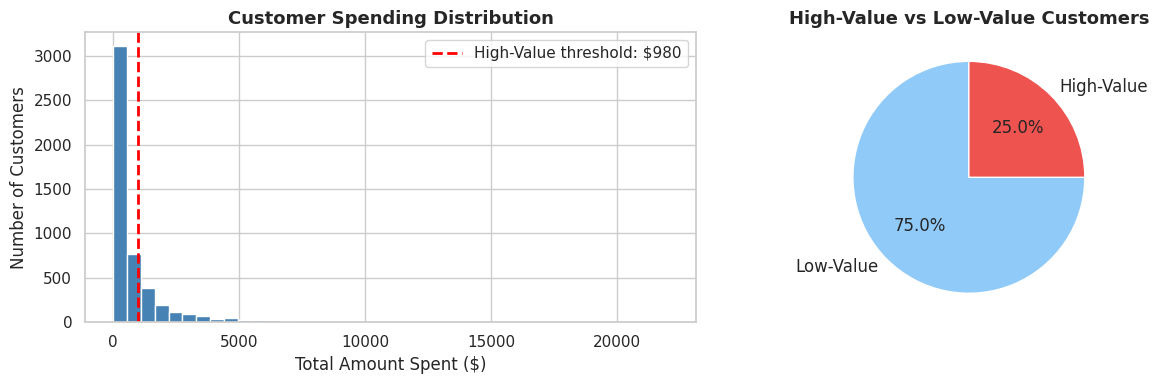

📌 Interpretation: The red dashed line separates the top 25% spenders (High-Value).
   Most customers fall below the threshold — high-value customers are a minority.


In [ ]:
# --- Spending Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: spending histogram
axes[0].hist(df['Total_Amount'], bins=40, color='steelblue', edgecolor='white')
axes[0].axvline(threshold, color='red', linestyle='--', linewidth=2,
                label=f'High-Value threshold: ${threshold:,.0f}')
axes[0].set_title('Customer Spending Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Amount Spent ($)')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()

# Right: High-Value vs Low-Value pie chart
counts = df['HighValue'].value_counts()
axes[1].pie(counts, labels=['Low-Value', 'High-Value'],
            autopct='%1.1f%%', colors=['#90CAF9', '#EF5350'],
            startangle=90, textprops={'fontsize': 12})
axes[1].set_title('High-Value vs Low-Value Customers', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print('📌 Interpretation: The red dashed line separates the top 25% spenders (High-Value).')
print('   Most customers fall below the threshold — high-value customers are a minority.')

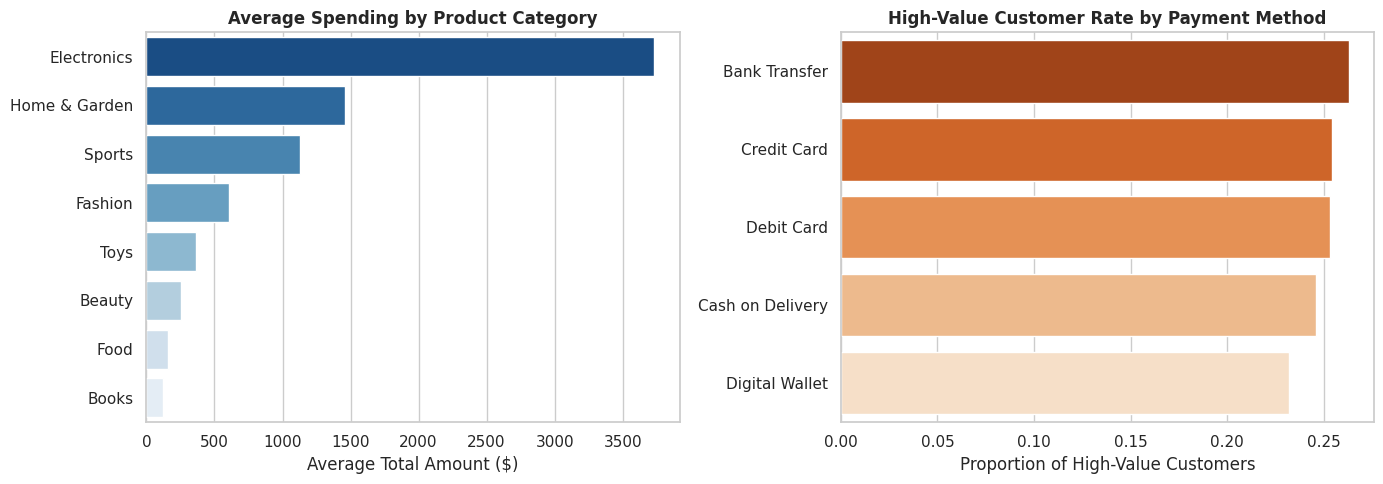

📌 Interpretation:
   Left:  Which product categories generate the highest average revenue.
   Right: Which payment methods are most associated with high-value customers.


In [ ]:
# --- Spending by Product Category & Payment Method ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average spend per product category
cat_spend = df.groupby('Product_Category')['Total_Amount'].mean().sort_values(ascending=False)
sns.barplot(x=cat_spend.values, y=cat_spend.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Average Spending by Product Category', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Total Amount ($)')
axes[0].set_ylabel('')

# High-Value rate by payment method
pay_hv = df.groupby('Payment_Method')['HighValue'].mean().sort_values(ascending=False)
sns.barplot(x=pay_hv.values, y=pay_hv.index, ax=axes[1], palette='Oranges_r')
axes[1].set_title('High-Value Customer Rate by Payment Method', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Proportion of High-Value Customers')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   Left:  Which product categories generate the highest average revenue.')
print('   Right: Which payment methods are most associated with high-value customers.')

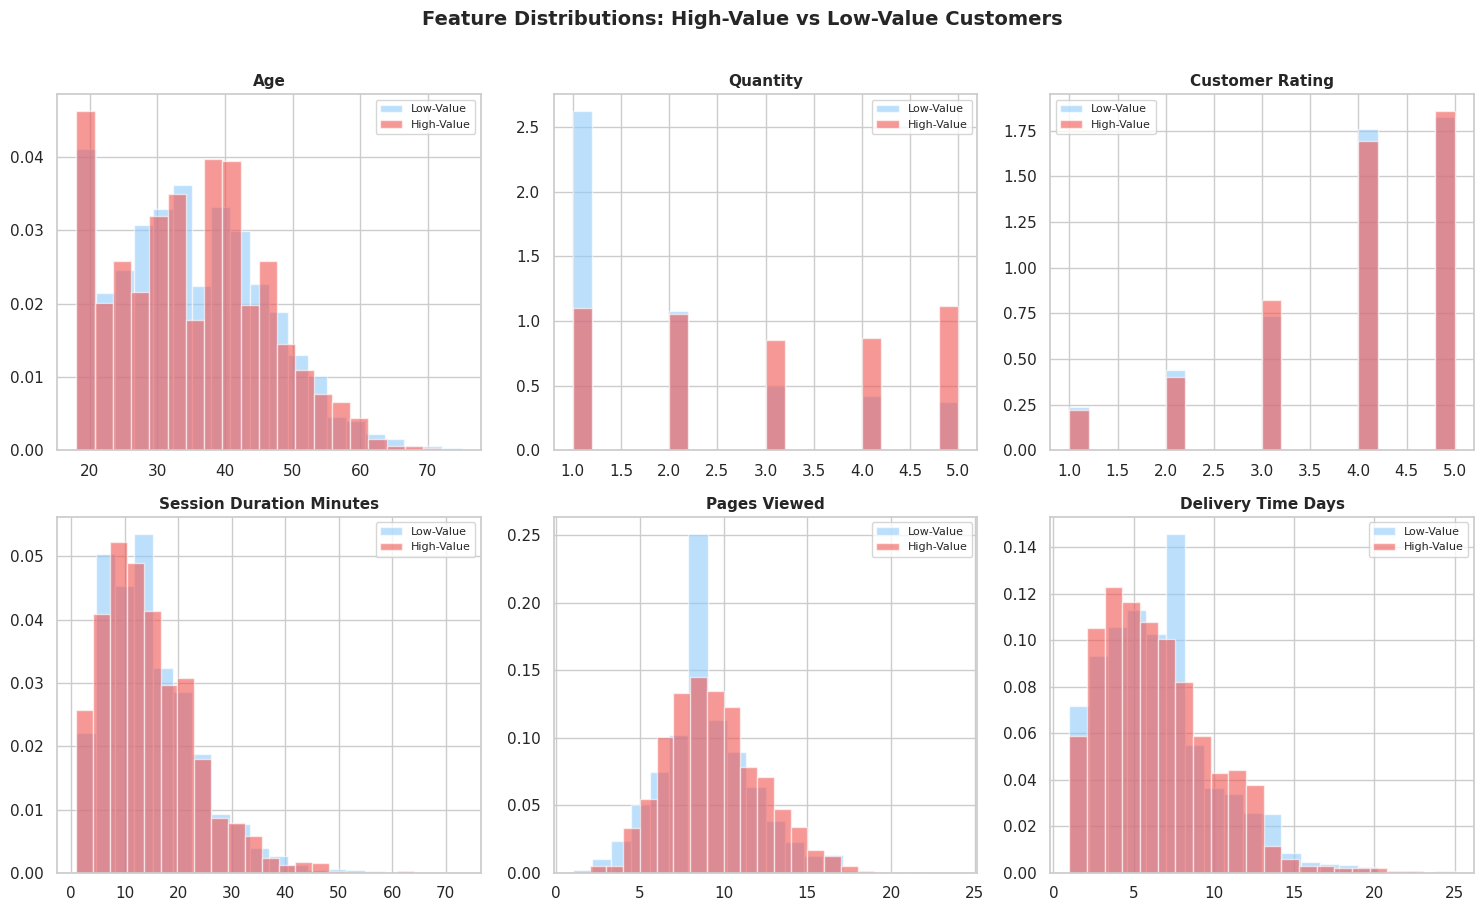

📌 Interpretation: These charts show whether each feature looks different
   between High-Value (red) and Low-Value (blue) customers.
   Overlapping distributions = feature is less useful for prediction.
   Separated distributions = feature helps distinguish customer value.


In [ ]:
# --- Feature Comparison: High-Value vs Low-Value customers ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

compare_cols = ['Age', 'Quantity', 'Customer_Rating',
                'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days']
colors = ['#90CAF9', '#EF5350']  # Blue=Low, Red=High

for ax, col in zip(axes, compare_cols):
    for val, label, color in [(0, 'Low-Value', colors[0]), (1, 'High-Value', colors[1])]:
        subset = df[df['HighValue'] == val][col]
        ax.hist(subset, bins=20, color=color, alpha=0.6, label=label, density=True)
    ax.set_title(col.replace('_', ' '), fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Feature Distributions: High-Value vs Low-Value Customers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('📌 Interpretation: These charts show whether each feature looks different')
print('   between High-Value (red) and Low-Value (blue) customers.')
print('   Overlapping distributions = feature is less useful for prediction.')
print('   Separated distributions = feature helps distinguish customer value.')

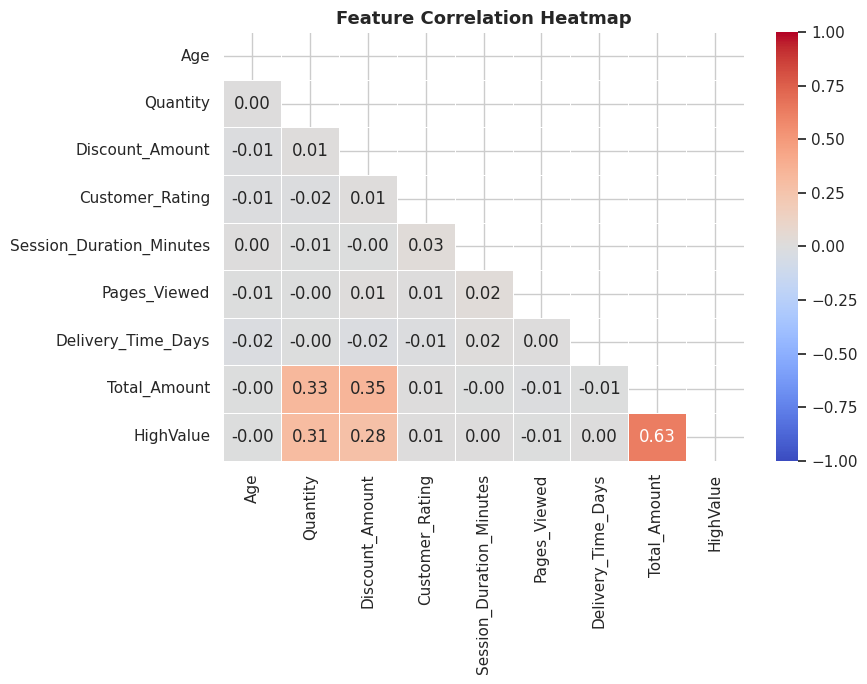

📌 Interpretation:
   Values close to +1 = strong positive correlation (features move together).
   Values close to -1 = strong negative correlation (features move opposite).
   Values close to  0 = little or no linear relationship.
   The last row shows how each feature correlates with HighValue (our target).


In [ ]:
# --- Correlation Heatmap ---
corr_cols = feature_cols + ['Total_Amount', 'HighValue']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # hide upper triangle
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            mask=mask, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Feature Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   Values close to +1 = strong positive correlation (features move together).')
print('   Values close to -1 = strong negative correlation (features move opposite).')
print('   Values close to  0 = little or no linear relationship.')
print('   The last row shows how each feature correlates with HighValue (our target).')

---
## Step 4 — PCA (Principal Component Analysis)

**What is PCA?**  
PCA takes our 7 features and compresses them into fewer dimensions while keeping as much information as possible. Think of it as "summarizing" the data.

**Why do we use it here?**  
- K-Means (next step) works better with fewer, uncorrelated dimensions
- PCA lets us visualize customers on a 2D plot
- It removes noise from the data

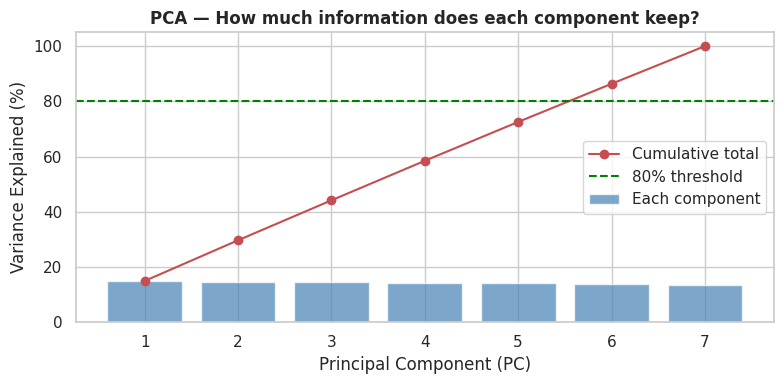

📌 We need 6 components to keep 80% of the information.
   This reduces our 7 features down to 6 components.


In [ ]:
# --- How much information does each component capture? ---
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(explained)+1), explained * 100,
       color='steelblue', alpha=0.7, label='Each component')
ax.plot(range(1, len(explained)+1), cumulative * 100,
        'ro-', markersize=6, label='Cumulative total')
ax.axhline(80, color='green', linestyle='--', label='80% threshold')
ax.set_xlabel('Principal Component (PC)')
ax.set_ylabel('Variance Explained (%)')
ax.set_title('PCA — How much information does each component keep?',
             fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

n_comp = int(np.argmax(cumulative >= 0.80)) + 1
print(f'📌 We need {n_comp} components to keep 80% of the information.')
print(f'   This reduces our {X_scaled.shape[1]} features down to {n_comp} components.')

In [ ]:
# --- Apply PCA ---
# We use the number of components that keep 80% of variance
pca     = PCA(n_components=n_comp, random_state=42)
X_pca   = pca.fit_transform(X_scaled)

# Also create a 2D version just for visualization
pca_2d  = PCA(n_components=2, random_state=42)
X_2d    = pca_2d.fit_transform(X_scaled)

print(f'Original feature matrix : {X_scaled.shape}')
print(f'After PCA (for clustering): {X_pca.shape}')
print(f'Variance retained: {pca.explained_variance_ratio_.sum()*100:.1f}%')

Original feature matrix : (5000, 7)
After PCA (for clustering): (5000, 6)
Variance retained: 86.4%


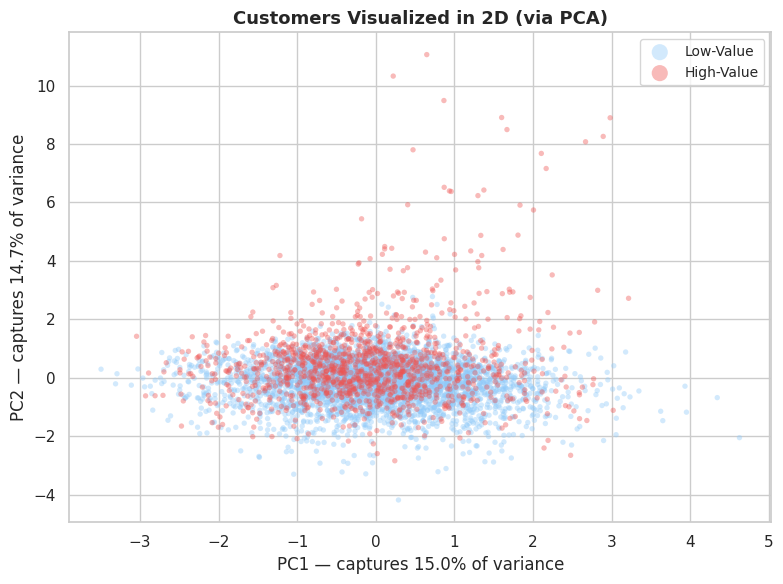

📌 Interpretation:
   Each dot = one customer, plotted using 2 PCA components.
   If blue and red points mix together → hard to separate by features alone.
   If they form distinct areas → features are useful for prediction.


In [ ]:
# --- Visualize customers in 2D (using the first 2 PCA components) ---
fig, ax = plt.subplots(figsize=(8, 6))

for val, label, color in [(0, 'Low-Value', '#90CAF9'), (1, 'High-Value', '#EF5350')]:
    mask = y.values == val
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
               c=color, label=label, alpha=0.4, s=15, edgecolors='none')

ax.set_xlabel(f'PC1 — captures {pca_2d.explained_variance_ratio_[0]*100:.1f}% of variance')
ax.set_ylabel(f'PC2 — captures {pca_2d.explained_variance_ratio_[1]*100:.1f}% of variance')
ax.set_title('Customers Visualized in 2D (via PCA)', fontsize=13, fontweight='bold')
ax.legend(markerscale=3, fontsize=10)
plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   Each dot = one customer, plotted using 2 PCA components.')
print('   If blue and red points mix together → hard to separate by features alone.')
print('   If they form distinct areas → features are useful for prediction.')

---
## Step 5 — K-Means Clustering (Customer Segmentation)

**What is K-Means?**  
K-Means groups customers into **k clusters** based on how similar they are. Customers in the same cluster behave similarly.

**Input:** PCA-reduced features (works better than raw features for K-Means)  
**Output:** Every customer gets assigned to a segment

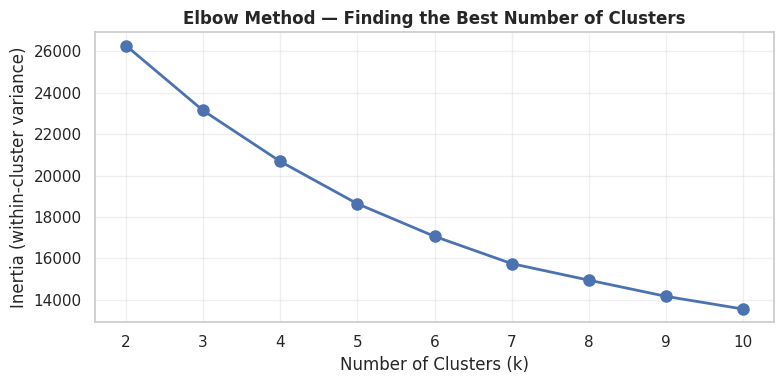

📌 How to read this chart:
   Look for the point where the curve bends like an "elbow".
   That k value = optimal number of clusters.
   We will use k=4 (a common and interpretable choice for customer segmentation).


In [ ]:
# --- Elbow Method: find the best number of clusters ---
# We try k=2 to k=10 and look for the 'elbow' where adding more clusters stops helping much

inertias = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, inertias, 'bo-', markersize=8, linewidth=2)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (within-cluster variance)')
ax.set_title('Elbow Method — Finding the Best Number of Clusters',
             fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('📌 How to read this chart:')
print('   Look for the point where the curve bends like an "elbow".')
print('   That k value = optimal number of clusters.')
print('   We will use k=4 (a common and interpretable choice for customer segmentation).')

In [ ]:
# --- Apply K-Means with k=4 ---
K = 4  # Number of segments

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_pca)

# --- Compute the profile of each cluster ---
profile = df.groupby('Cluster').agg(
    Num_Customers    = ('Customer_ID',              'count'),
    Avg_Spend        = ('Total_Amount',             'mean'),
    Avg_Rating       = ('Customer_Rating',          'mean'),
    Avg_Session_Min  = ('Session_Duration_Minutes', 'mean'),
    Avg_Pages        = ('Pages_Viewed',             'mean'),
    Avg_Quantity     = ('Quantity',                 'mean'),
    HighValue_Rate   = ('HighValue',                'mean'),
).round(2)

print('=== Cluster Profiles ===')
print(profile.to_string())
print()
print('📌 Look at Avg_Spend and HighValue_Rate to understand which cluster is most valuable.')

=== Cluster Profiles ===
         Num_Customers  Avg_Spend  Avg_Rating  Avg_Session_Min  Avg_Pages  Avg_Quantity  HighValue_Rate
Cluster                                                                                                
0                  127    4365.86        4.10            14.19       8.91          2.15            0.92
1                 1282    1636.48        4.05            15.77       8.85          4.19            0.41
2                 2378     566.19        4.48            15.05       8.78          1.38            0.15
3                 1213     755.75        2.60            12.41       9.55          1.79            0.20

📌 Look at Avg_Spend and HighValue_Rate to understand which cluster is most valuable.


In [ ]:
# --- Assign meaningful names to each cluster based on its profile ---
# We rank clusters by their average spend to label them
spend_rank = profile['Avg_Spend'].rank(ascending=False).astype(int)

label_map = {
    rank: name for rank, name in zip(
        sorted(spend_rank.values),
        ['Champions', 'Loyal Customers', 'Occasional Buyers', 'At-Risk']
    )
}
cluster_to_label = {cluster: label_map[rank] for cluster, rank in spend_rank.items()}

df['Segment'] = df['Cluster'].map(cluster_to_label)

print('Cluster → Segment mapping:')
for c, s in cluster_to_label.items():
    print(f'  Cluster {c}  →  {s}  (avg spend: ${profile.loc[c, "Avg_Spend"]:,.0f})')

Cluster → Segment mapping:
  Cluster 0  →  Champions  (avg spend: $4,366)
  Cluster 1  →  Loyal Customers  (avg spend: $1,636)
  Cluster 2  →  At-Risk  (avg spend: $566)
  Cluster 3  →  Occasional Buyers  (avg spend: $756)


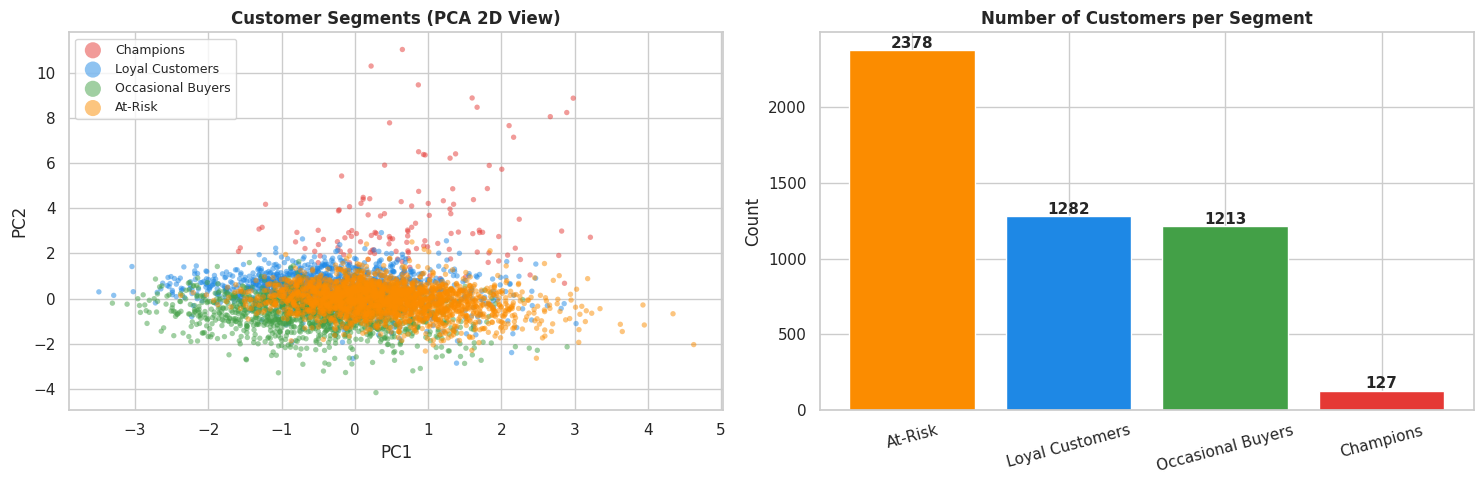

📌 Interpretation:
   Left:  Each color = one customer segment, plotted in PCA 2D space.
   Right: How many customers belong to each segment.


In [ ]:
# --- Visualize the customer segments ---
SEG_COLORS = {
    'Champions':        '#E53935',
    'Loyal Customers':  '#1E88E5',
    'Occasional Buyers':'#43A047',
    'At-Risk':          '#FB8C00'
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: PCA 2D scatter colored by segment
for seg, color in SEG_COLORS.items():
    mask = df['Segment'] == seg
    if mask.sum() == 0: continue
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1],
                    c=color, label=seg, alpha=0.5, s=15, edgecolors='none')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].set_title('Customer Segments (PCA 2D View)', fontsize=12, fontweight='bold')
axes[0].legend(markerscale=3, fontsize=9)

# Right: Number of customers per segment
seg_counts = df['Segment'].value_counts()
bar_colors = [SEG_COLORS.get(s, '#999') for s in seg_counts.index]
bars = axes[1].bar(seg_counts.index, seg_counts.values, color=bar_colors, edgecolor='white')
for bar, val in zip(bars, seg_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 str(val), ha='center', fontsize=11, fontweight='bold')
axes[1].set_title('Number of Customers per Segment', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   Left:  Each color = one customer segment, plotted in PCA 2D space.')
print('   Right: How many customers belong to each segment.')

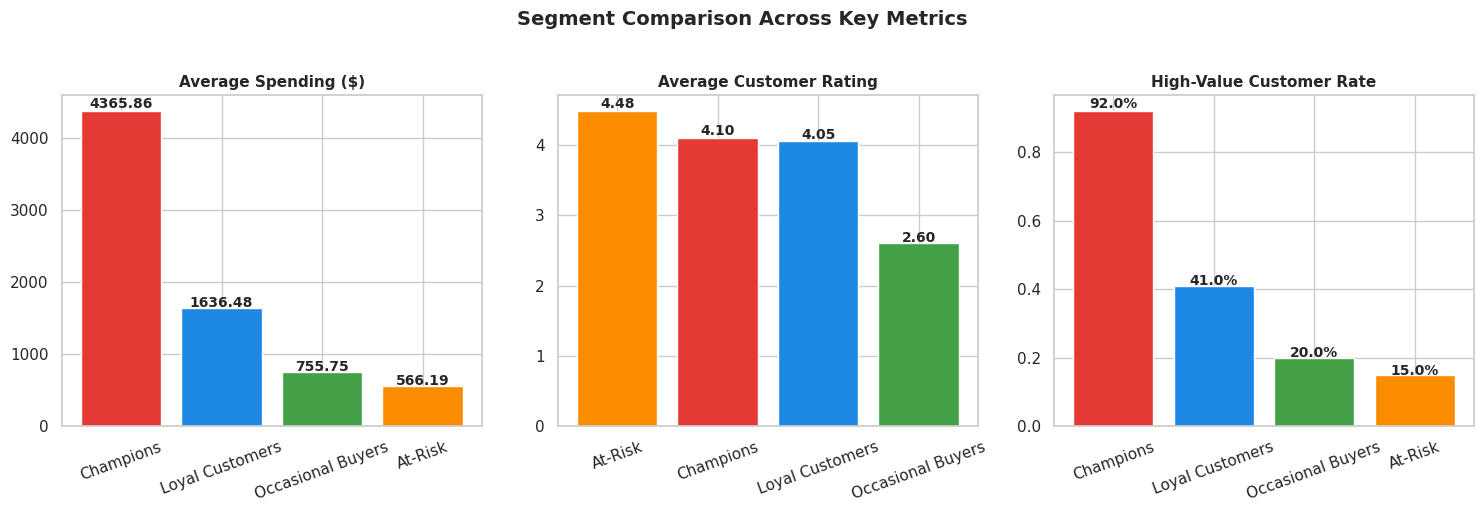

📌 Interpretation:
   These charts answer: how does each segment differ in spending, satisfaction, and value?
   Champions spend the most and have the highest high-value rate.
   At-Risk customers spend less and engage less — they need re-activation.


In [ ]:
# --- Compare segments across key metrics ---
seg_profile = df.groupby('Segment').agg(
    Avg_Spend      = ('Total_Amount',             'mean'),
    Avg_Rating     = ('Customer_Rating',          'mean'),
    Avg_Session    = ('Session_Duration_Minutes', 'mean'),
    HighValue_Rate = ('HighValue',                'mean')
).round(2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics    = ['Avg_Spend', 'Avg_Rating', 'HighValue_Rate']
titles     = ['Average Spending ($)', 'Average Customer Rating', 'High-Value Customer Rate']

for ax, metric, title in zip(axes, metrics, titles):
    vals   = seg_profile[metric].sort_values(ascending=False)
    colors = [SEG_COLORS.get(s, '#999') for s in vals.index]
    bars   = ax.bar(vals.index, vals.values, color=colors, edgecolor='white')
    for bar, val in zip(bars, vals.values):
        label = f'{val*100:.1f}%' if 'Rate' in metric else f'{val:.2f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                label, ha='center', fontsize=10, fontweight='bold')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Segment Comparison Across Key Metrics', fontsize=14,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   These charts answer: how does each segment differ in spending, satisfaction, and value?')
print('   Champions spend the most and have the highest high-value rate.')
print('   At-Risk customers spend less and engage less — they need re-activation.')

---
## Step 6 — Random Forest (Predict High-Value Customers)

**What is Random Forest?**  
Random Forest builds many decision trees and combines their predictions. It learns which customer features are most associated with high spending.

**Input:** Behavioral features (Age, Quantity, Session time, etc.)  
**Output:** A prediction — will this customer be High-Value or not?

> **Note:** We train on the original features (not PCA), so we can interpret which features matter most.

In [ ]:
# --- Split data into training (80%) and testing (20%) sets ---
# We train the model on 80% of the data, and test it on the remaining 20%

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set : {len(X_train):,} customers')
print(f'Testing set  : {len(X_test):,} customers')
print(f'High-Value % in training: {y_train.mean()*100:.1f}%')

Training set : 4,000 customers
Testing set  : 1,000 customers
High-Value % in training: 25.0%


In [ ]:
# --- Train the Random Forest model ---
rf = RandomForestClassifier(
    n_estimators  = 100,    # Number of trees
    max_depth     = 6,      # How deep each tree can grow
    class_weight  = 'balanced',  # Handle class imbalance
    random_state  = 42
)
rf.fit(X_train, y_train)

# --- Evaluate on the test set ---
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)
print('=== Model Performance ===')
print(classification_report(y_test, y_pred, target_names=['Low-Value', 'High-Value']))
print(f'ROC-AUC Score: {auc:.3f}')
print()
print('📌 How to read these metrics:')
print('   Precision : Of all customers predicted High-Value, how many actually are?')
print('   Recall    : Of all true High-Value customers, how many did the model catch?')
print('   F1-Score  : Balance between precision and recall (higher = better).')
print('   ROC-AUC   : Overall model quality (0.5 = random, 1.0 = perfect).')

=== Model Performance ===
              precision    recall  f1-score   support

   Low-Value       0.88      0.75      0.81       750
  High-Value       0.47      0.68      0.56       250

    accuracy                           0.73      1000
   macro avg       0.68      0.71      0.68      1000
weighted avg       0.78      0.73      0.75      1000

ROC-AUC Score: 0.780

📌 How to read these metrics:
   Precision : Of all customers predicted High-Value, how many actually are?
   Recall    : Of all true High-Value customers, how many did the model catch?
   F1-Score  : Balance between precision and recall (higher = better).
   ROC-AUC   : Overall model quality (0.5 = random, 1.0 = perfect).


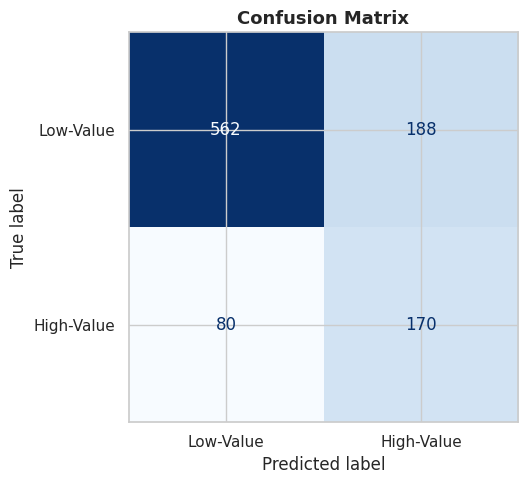

📌 How to read the Confusion Matrix:
   Top-left    : Correctly predicted Low-Value  (True Negatives)
   Bottom-right: Correctly predicted High-Value (True Positives)
   Top-right   : Low-Value predicted as High-Value (False Positives) — costly mistake
   Bottom-left : High-Value predicted as Low-Value (False Negatives) — missed opportunities


In [ ]:
# --- Confusion Matrix ---
# Shows how many predictions were correct vs incorrect
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Low-Value', 'High-Value'],
    cmap='Blues', colorbar=False, ax=ax
)
ax.set_title('Confusion Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('📌 How to read the Confusion Matrix:')
print('   Top-left    : Correctly predicted Low-Value  (True Negatives)')
print('   Bottom-right: Correctly predicted High-Value (True Positives)')
print('   Top-right   : Low-Value predicted as High-Value (False Positives) — costly mistake')
print('   Bottom-left : High-Value predicted as Low-Value (False Negatives) — missed opportunities')

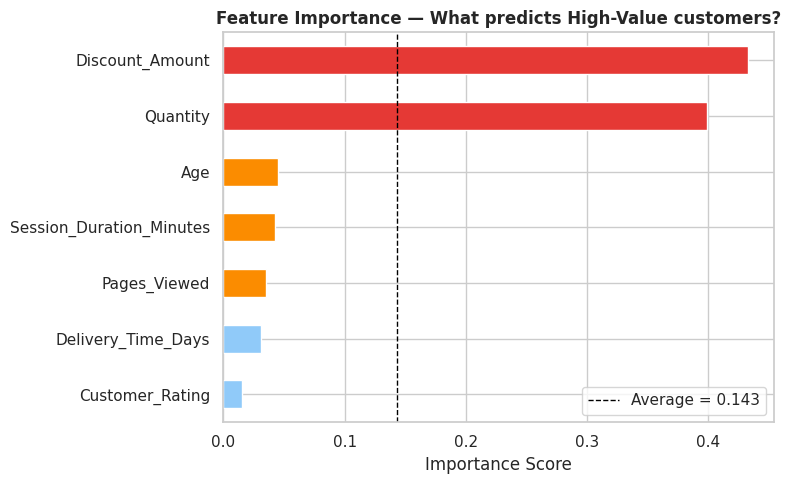

📌 Interpretation:
   Red bars   = most important features (above average importance).
   Orange bars= moderately important.
   Blue bars  = less important for predicting High-Value customers.

   Top 3 features:
     → Discount_Amount (importance = 0.433)
     → Quantity (importance = 0.399)
     → Age (importance = 0.045)


In [ ]:
# --- Feature Importance: which features matter most? ---
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#E53935' if v >= importances.quantile(0.67) else
          '#FB8C00' if v >= importances.quantile(0.33) else '#90CAF9'
          for v in importances]
importances.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.set_title('Feature Importance — What predicts High-Value customers?',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.axvline(importances.mean(), color='black', linestyle='--',
           linewidth=1, label=f'Average = {importances.mean():.3f}')
ax.legend()
plt.tight_layout()
plt.show()

print('📌 Interpretation:')
print('   Red bars   = most important features (above average importance).')
print('   Orange bars= moderately important.')
print('   Blue bars  = less important for predicting High-Value customers.')
top3 = importances.sort_values(ascending=False).head(3)
print(f'\n   Top 3 features:')
for feat, val in top3.items():
    print(f'     → {feat} (importance = {val:.3f})')

---
## Step 7 — Business Summary & Recommendations

In [ ]:
# --- Final segment summary table ---
final_summary = df.groupby('Segment').agg(
    Customers      = ('Customer_ID',              'count'),
    Avg_Spending   = ('Total_Amount',             'mean'),
    Avg_Rating     = ('Customer_Rating',          'mean'),
    Avg_Session    = ('Session_Duration_Minutes', 'mean'),
    HighValue_Pct  = ('HighValue',               lambda x: f"{x.mean()*100:.1f}%")
).round(2)

print('=== Final Customer Segment Profiles ===')
print(final_summary.to_string())

=== Final Customer Segment Profiles ===
                   Customers  Avg_Spending  Avg_Rating  Avg_Session HighValue_Pct
Segment                                                                          
At-Risk                 2378        566.19        4.48        15.05         15.1%
Champions                127       4365.86        4.10        14.19         92.1%
Loyal Customers         1282       1636.48        4.05        15.77         41.1%
Occasional Buyers       1213        755.75        2.60        12.41         20.3%


In [ ]:
# --- Marketing Recommendations ---
print('=' * 60)
print('  MARKETING ACTION PLAN BY SEGMENT')
print('=' * 60)

actions = {
    'Champions': [
        'Reward with VIP loyalty programs',
        'Give early access to new products',
        'Send personalized thank-you campaigns'
    ],
    'Loyal Customers': [
        'Upsell premium or complementary products',
        'Offer bundle deals based on purchase history',
        'Invite to a referral or ambassador program'
    ],
    'Occasional Buyers': [
        'Send targeted promotions based on past categories',
        'Use seasonal or event-based re-engagement emails',
        'Send abandoned-cart reminders'
    ],
    'At-Risk': [
        'Send a time-limited win-back discount',
        'Ask for feedback to understand their dissatisfaction',
        'Highlight new products or improvements since last purchase'
    ]
}

icons = {'Champions': '⭐', 'Loyal Customers': '💙',
         'Occasional Buyers': '🛒', 'At-Risk': '⚠️'}

for seg, tips in actions.items():
    print(f'\n{icons[seg]}  {seg}')
    for tip in tips:
        print(f'    • {tip}')

print()
print('=' * 60)
print('  RANDOM FOREST MODEL SUMMARY')
print('=' * 60)
print(f'  ROC-AUC Score  : {auc:.3f}  (1.0 = perfect, 0.5 = random guessing)')
top_feat = importances.sort_values(ascending=False).index[0]
print(f'  Most predictive feature: {top_feat}')
print()
print('  💡 Business Use: Score every new customer using this model.')
print('     Focus marketing budget on customers with the highest predicted')
print('     probability of being High-Value.')

  MARKETING ACTION PLAN BY SEGMENT

⭐  Champions
    • Reward with VIP loyalty programs
    • Give early access to new products
    • Send personalized thank-you campaigns

💙  Loyal Customers
    • Upsell premium or complementary products
    • Offer bundle deals based on purchase history
    • Invite to a referral or ambassador program

🛒  Occasional Buyers
    • Send targeted promotions based on past categories
    • Use seasonal or event-based re-engagement emails
    • Send abandoned-cart reminders

⚠️  At-Risk
    • Send a time-limited win-back discount
    • Ask for feedback to understand their dissatisfaction
    • Highlight new products or improvements since last purchase

  RANDOM FOREST MODEL SUMMARY
  ROC-AUC Score  : 0.780  (1.0 = perfect, 0.5 = random guessing)
  Most predictive feature: Discount_Amount

  💡 Business Use: Score every new customer using this model.
     Focus marketing budget on customers with the highest predicted
     probability of being High-Value.


In [ ]:
# ── LIVE PREDICTION: Score a real customer ──────────────────────────

# Fill in your customer's actual info here:
new_customer = {
    'Age':                      34,     # Customer's age
    'Quantity':                  2,     # Number of items in the order
    'Discount_Amount':        15.00,    # Dollar value of discount received
    'Customer_Rating':           4,     # Their satisfaction rating (1–5)
    'Session_Duration_Minutes': 12.5,   # Minutes spent browsing
    'Pages_Viewed':              8,     # Pages they visited
    'Delivery_Time_Days':        3,     # How many days delivery took
}

# --- Convert to a DataFrame (model expects this format) ---
import pandas as pd
new_df = pd.DataFrame([new_customer])

# --- Apply the SAME scaler used during training ---
new_scaled = scaler.transform(new_df[feature_cols])

# --- Predict ---
prediction  = rf.predict(new_scaled)[0]
probability = rf.predict_proba(new_scaled)[0][1]  # Probability of being High-Value

# --- Display results ---
label = "⭐ HIGH-VALUE" if prediction == 1 else "🔵 Low-Value"
print(f"Customer Prediction : {label}")
print(f"High-Value Probability : {probability*100:.1f}%")
print()
if prediction == 1:
    print("✅ Recommended Action: Enroll in VIP loyalty program, offer early access deals.")
else:
    print("📢 Recommended Action: Send targeted promotions or re-engagement campaign.")

Customer Prediction : 🔵 Low-Value
High-Value Probability : 31.2%

📢 Recommended Action: Send targeted promotions or re-engagement campaign.


---
## ✅ Project Conclusion

### What we built

| Method | What it does | Key Output |
|--------|-------------|------------|
| **PCA** | Reduces 7 features into fewer dimensions | Better clustering + 2D visualization |
| **K-Means** | Groups similar customers together | 4 customer segments |
| **Random Forest** | Learns to predict high-value customers | Prediction + feature importance |

### Key Findings

1. **Customer value** is driven primarily by behavioral signals — the model identifies which features best predict high spending.

2. **Segmentation** reveals 4 distinct customer groups, each requiring a different marketing strategy:
   - **Champions** → Protect and reward them
   - **Loyal Customers** → Upsell and deepen the relationship
   - **Occasional Buyers** → Convert them into regulars
   - **At-Risk** → Re-engage before they churn

3. **Random Forest** can predict whether a new customer will be high-value, allowing the company to **prioritize marketing spend** before the customer even makes a second purchase.